# PathSnap - 01 Dataset Exploration (EDA)

**Partitions used:** `train` (80 trips) and `student_test` (10 trips). The evaluator partition is not available and is never touched.

Goals (from *Dataset Exploration.pdf* section 4): inventory, observations per trip, file sizes, types, missing/invalid GPS,
timestamp ordering and gaps, geographic extent, road-network size and connectivity, isolated nodes / components,
anomalies, and the structure of the reference routes.

In [1]:
import sys, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import shapely
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
import folium

sys.path.insert(0, str(Path.cwd().parent / "src"))
from data import DATA_ROOT, PARTITIONS, list_trips, load_trip, haversine, to_local_xy

OUT = Path.cwd().parent / "outputs" / "eda"
(OUT / "plots").mkdir(parents=True, exist_ok=True); (OUT / "maps").mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)
print({p: len(list_trips(p)) for p in PARTITIONS})

{'train': 80, 'student_test': 10}


## 1. Raw file check (one trip)
Files have no headers. Column meanings are from the dataset document and verified below
(lon in [-180,180], lat in [-90,90], arc endpoints are valid node row indices, route values are valid arc row indices).

In [2]:
d = load_trip("train", "00000001")
for k in ["track", "nodes", "arcs", "route"]:
    print(f"--- {k}: shape={d[k].shape}, dtypes={dict(d[k].dtypes)}")
    print(d[k].head(3).to_string())

--- track: shape=(1315, 3), dtypes={'lon': dtype('float64'), 'lat': dtype('float64'), 't': dtype('float64')}
        lon        lat    t
0  8.595203  49.844053  1.0
1  8.595294  49.844441  2.0
2  8.595352  49.844883  3.0
--- nodes: shape=(88809, 2), dtypes={'lon': dtype('float64'), 'lat': dtype('float64')}
        lon        lat
0  8.581679  49.857880
1  8.584637  49.858295
2  8.580173  49.858567
--- arcs: shape=(165790, 2), dtypes={'u': dtype('int64'), 'v': dtype('int64')}
   u    v
0  0  281
1  0    1
2  0    5
--- route: shape=(525, 1), dtypes={'arc_id': dtype('int64')}
   arc_id
0    2641
1   64973
2  133948


## 2. Per-trip inventory and quality statistics
Distances: haversine for GPS steps / arc lengths. For point-to-segment distances each trip is projected to a local
equirectangular plane (metres) around its own centroid; the projection error vs. haversine is measured per trip (`proj_err_max_pct`).

In [3]:
def arc_lines(xy_nodes, arcs):
    seg = np.stack([xy_nodes[arcs.u.values], xy_nodes[arcs.v.values]], axis=1)
    return shapely.linestrings(seg)

def trip_stats(part, tid):
    d = load_trip(part, tid)
    tr, nd, ar, rt = d["track"], d["nodes"], d["arcs"], d["route"]
    base = DATA_ROOT / part / tid / tid
    s = {"partition": part, "trip_id": tid}
    for ext in ["track", "nodes", "arcs", "route"]:
        p = base.with_suffix("." + ext)
        s[f"{ext}_kb"] = round(p.stat().st_size / 1024, 1) if p.exists() else np.nan

    # --- GPS track
    lon, lat, t = tr.lon.values, tr.lat.values, tr.t.values
    s["n_points"] = len(tr)
    s["track_nan"] = int(tr.isna().sum().sum())
    s["invalid_coord"] = int(((np.abs(lon) > 180) | (np.abs(lat) > 90)).sum())
    dt = np.diff(t)
    s["t_non_increasing"] = int((dt <= 0).sum())
    s["dt_pct_1s"] = float((dt == 1).mean())
    s["dt_max_s"] = float(dt.max())
    s["n_gaps_gt10s"] = int((dt > 10).sum())
    s["duration_min"] = (t[-1] - t[0]) / 60
    step = haversine(lon[:-1], lat[:-1], lon[1:], lat[1:])
    s["gps_path_km"] = step.sum() / 1000
    speed = step / np.where(dt > 0, dt, np.nan) * 3.6
    s["speed_median_kmh"] = np.nanmedian(speed)
    s["speed_p99_kmh"] = np.nanpercentile(speed, 99)
    s["n_jumps_gt200kmh"] = int((speed > 200).sum())
    s["stationary_steps"] = int((step == 0).sum())
    s["lon_min"], s["lon_max"], s["lat_min"], s["lat_max"] = lon.min(), lon.max(), lat.min(), lat.max()
    lon0, lat0 = lon.mean(), lat.mean()
    s["lon_c"], s["lat_c"] = lon0, lat0
    gx, gy = to_local_xy(lon, lat, lon0, lat0)
    s["extent_x_km"], s["extent_y_km"] = np.ptp(gx) / 1000, np.ptp(gy) / 1000
    hv = haversine(lon0, lat0, lon, lat); far = hv > 100
    s["proj_err_max_pct"] = float((np.abs(np.hypot(gx, gy)[far] - hv[far]) / hv[far]).max() * 100) if far.any() else 0.0

    # --- road network
    n = len(nd); u, v = ar.u.values, ar.v.values
    s["n_nodes"], s["n_arcs"] = n, len(ar)
    s["arc_bad_node_ref"] = int(((u < 0) | (u >= n) | (v < 0) | (v >= n)).sum())
    s["self_loops"] = int((u == v).sum())
    s["dup_arcs"] = int(ar.duplicated().sum())
    key = u * n + v
    s["two_way_frac"] = float(np.isin(v * n + u, key).mean())
    used = np.zeros(n, bool); used[u] = True; used[v] = True
    s["isolated_nodes"] = int((~used).sum())
    G = csr_matrix((np.ones(len(u)), (u, v)), shape=(n, n))
    nw, lw = connected_components(G, directed=True, connection="weak")
    ns, ls = connected_components(G, directed=True, connection="strong")
    s["weak_components"] = int(nw - (~used).sum())          # ignore isolated nodes
    s["largest_wcc_frac"] = np.bincount(lw[used]).max() / used.sum()
    s["strong_components"] = int(ns - (~used).sum())
    s["largest_scc_frac"] = np.bincount(ls[used]).max() / used.sum()
    arc_len = haversine(nd.lon.values[u], nd.lat.values[u], nd.lon.values[v], nd.lat.values[v])
    s["arc_len_median_m"], s["arc_len_max_m"] = np.median(arc_len), arc_len.max()
    s["zero_len_arcs"] = int((arc_len == 0).sum())

    # --- reference route
    r = rt.arc_id.values
    s["n_route_arcs"] = len(r)
    s["route_bad_ids"] = int(((r < 0) | (r >= len(ar))).sum())
    s["route_connected_frac"] = float((v[r[:-1]] == u[r[1:]]).mean())
    s["route_repeat_arcs"] = len(r) - len(np.unique(r))
    s["route_km"] = arc_len[r].sum() / 1000
    s["route_vs_gps_len"] = s["route_km"] / max(s["gps_path_km"], 1e-9)

    # --- GPS to network distances (local metres)
    nx_, ny_ = to_local_xy(nd.lon.values, nd.lat.values, lon0, lat0)
    xy = np.column_stack([nx_, ny_])
    pts = shapely.points(gx, gy)
    _, d_any = shapely.STRtree(arc_lines(xy, ar)).query_nearest(pts, return_distance=True, all_matches=False)
    _, d_rt = shapely.STRtree(arc_lines(xy, ar.iloc[np.unique(r)])).query_nearest(pts, return_distance=True, all_matches=False)
    s["gps2arc_median_m"], s["gps2arc_p95_m"] = np.median(d_any), np.percentile(d_any, 95)
    s["gps2route_median_m"], s["gps2route_p95_m"] = np.median(d_rt), np.percentile(d_rt, 95)
    s["gps2route_max_m"] = d_rt.max()
    s["gps_far_from_route_frac"] = float((d_rt > 50).mean())
    return s, {"dt": dt, "speed": speed, "d_any": d_any, "d_route": d_rt}

t0 = time.time()
rows, extras = [], {}
for part in PARTITIONS:
    for tid in list_trips(part):
        s, e = trip_stats(part, tid)
        rows.append(s); extras[(part, tid)] = e
inv = pd.DataFrame(rows)
inv.to_csv(OUT / "inventory.csv", index=False)
print(f"{len(inv)} trips processed in {time.time()-t0:.0f}s -> outputs/eda/inventory.csv")
inv.head()

90 trips processed in 3s -> outputs/eda/inventory.csv


,partition,trip_id,track_kb,nodes_kb,arcs_kb,route_kb,n_points,track_nan,invalid_coord,t_non_increasing,dt_pct_1s,dt_max_s,n_gaps_gt10s,duration_min,gps_path_km,speed_median_kmh,speed_p99_kmh,n_jumps_gt200kmh,stationary_steps,lon_min,lon_max,lat_min,lat_max,lon_c,lat_c,extent_x_km,extent_y_km,proj_err_max_pct,n_nodes,n_arcs,arc_bad_node_ref,self_loops,dup_arcs,two_way_frac,isolated_nodes,weak_components,largest_wcc_frac,strong_components,largest_scc_frac,arc_len_median_m,arc_len_max_m,zero_len_arcs,n_route_arcs,route_bad_ids,route_connected_frac,route_repeat_arcs,route_km,route_vs_gps_len,gps2arc_median_m,gps2arc_p95_m,gps2route_median_m,gps2route_p95_m,gps2route_max_m,gps_far_from_route_frac
0,train,00000001,40.0,1647.8,1902.8,3.0,1315,0,0,0,0.980974,16.0,1,22.616667,50.186254,148.579972,230.434206,149,0,8.570524,8.647860,49.844053,50.211882,8.605599,50.088368,5.517410,40.900775,0.006447,88809,165790,0,0,292,0.818819,0,175,0.977986,1942,0.957099,20.198040,1106.458542,8,525,0,1.000000,0,49.854610,0.993392,3.695808,9.735097,4.289789,12.355568,27.210642,0.00000
1,train,00000002,232.5,155.0,152.9,1.4,7243,0,0,0,0.974455,160.0,41,148.885933,55.872411,25.404023,73.752644,0,1,10.999961,11.050902,47.658344,47.695459,11.032568,47.683925,3.813380,4.127005,0.007992,7936,16139,0,0,0,0.996964,0,14,0.976562,14,0.976562,16.043399,378.377013,0,262,0,0.996169,0,7.963186,0.142524,5.386693,67.478094,5.662180,242.221046,569.485935,0.11984
2,train,00000003,25.6,178.5,171.6,0.4,821,0,0,0,0.996341,2.0,0,13.716667,8.420171,33.470155,93.390568,0,0,37.154202,37.201595,55.977135,56.007585,37.177362,55.987684,2.947812,3.385890,0.008198,9138,18028,0,0,6,0.909807,0,42,0.943861,167,0.901182,17.277177,619.235976,4,79,0,1.000000,0,5.004547,0.594352,3.300417,11.775372,4.433556,13.967470,25.767205,0.00000
3,train,00000004,34.2,143.6,146.2,1.5,1064,0,0,0,0.538100,51.0,215,86.950000,27.891064,21.394803,75.485960,0,0,12.342280,12.459615,52.590308,52.718960,12.424218,52.641499,7.916969,14.305469,0.028394,7350,15499,0,0,5,0.975611,0,12,0.986939,14,0.986667,35.030152,1142.715676,2,320,0,1.000000,0,25.546780,0.915949,7.321031,27.474980,8.503561,29.475580,44.539346,0.00000
4,train,00000005,32.6,17.5,12.1,0.4,1045,0,0,0,1.000000,1.0,0,17.400000,31.325987,111.213187,169.304529,1,0,35.485577,35.544315,49.357581,49.613085,35.503261,49.486068,4.242997,28.410788,0.005482,898,1579,0,0,0,0.815706,0,3,0.988864,153,0.635857,84.902965,3613.063614,0,105,0,1.000000,0,30.862433,0.985202,4.440263,12.842444,4.526539,13.234733,26.944581,0.00000


## 3. Summary by partition

In [4]:
cols = ["n_points", "duration_min", "gps_path_km", "dt_pct_1s", "dt_max_s", "n_nodes", "n_arcs", "n_route_arcs",
        "gps2route_median_m", "gps2route_p95_m", "two_way_frac", "largest_wcc_frac", "largest_scc_frac"]
summary = inv.groupby("partition")[cols].describe().T.round(3)
summary.to_csv(OUT / "summary_by_partition.csv")
summary

partition               student_test     train
n_points         count        10.000    80.000
                 mean       1916.000  2605.212
                 std        1335.432  3312.345
                 min         262.000   361.000
                 25%         917.750   945.750
...                              ...       ...
largest_scc_frac min           0.817     0.636
                 25%           0.947     0.938
                 50%           0.961     0.964
                 75%           0.972     0.982
                 max           0.984     1.000

[104 rows x 2 columns]

In [5]:
files = inv.groupby("partition")[["track_kb", "nodes_kb", "arcs_kb", "route_kb"]].agg(["count", "sum", "max"]).round(0)
print("File availability (count per partition) and sizes in KB:"); files

File availability (count per partition) and sizes in KB:


track_kb                nodes_kb                  arcs_kb                  route_kb             
                count     sum    max    count      sum     max   count      sum     max    count    sum   max
partition                                                                                                    
student_test       10   611.0  130.0       10   1779.0   520.0      10   1858.0   610.0       10   18.0   7.0
train              80  6712.0  612.0       80  37531.0  2876.0      80  43230.0  3767.0       80  162.0  12.0

## 4. Missing / invalid values and timestamp checks

In [6]:
checks = ["track_nan", "invalid_coord", "t_non_increasing", "arc_bad_node_ref", "route_bad_ids",
          "self_loops", "dup_arcs", "zero_len_arcs", "stationary_steps", "n_jumps_gt200kmh", "isolated_nodes"]
mv = inv.groupby("partition")[checks].sum().T
mv.columns = [f"total_{c}" for c in mv.columns]
mv["trips_affected"] = (inv[checks] > 0).sum().values
mv.to_csv(OUT / "missing_invalid_checks.csv"); mv

,total_student_test,total_train,trips_affected
track_nan,0,0,0
invalid_coord,0,0,0
t_non_increasing,0,0,0
arc_bad_node_ref,0,0,0
route_bad_ids,0,0,0
self_loops,2,22,9
dup_arcs,128,1775,60
zero_len_arcs,6,100,32
stationary_steps,0,6,5
n_jumps_gt200kmh,4,917,23


## 5. Anomalous trips

In [7]:
anom = inv[(inv.dt_max_s > 30) | (inv.n_jumps_gt200kmh > 0) | (inv.route_connected_frac < 1)
           | (inv.gps_far_from_route_frac > 0.01) | (inv.gps2route_max_m > 100)]
anom_cols = ["partition", "trip_id", "n_points", "dt_max_s", "n_gaps_gt10s", "n_jumps_gt200kmh",
             "route_connected_frac", "gps2route_p95_m", "gps2route_max_m", "gps_far_from_route_frac", "route_vs_gps_len"]
anom[anom_cols].sort_values("dt_max_s", ascending=False).to_csv(OUT / "anomalous_trips.csv", index=False)
anom[anom_cols].sort_values("dt_max_s", ascending=False)

,partition,trip_id,n_points,dt_max_s,n_gaps_gt10s,n_jumps_gt200kmh,route_connected_frac,gps2route_p95_m,gps2route_max_m,gps_far_from_route_frac,route_vs_gps_len
72,train,00000090,536,153064.0,6,0,1.000000,12.764316,23.706601,0.000000,0.924962
61,train,00000078,2909,52810.0,25,0,1.000000,15.749406,59.958492,0.001719,0.956133
55,train,00000069,2067,2658.0,2,0,0.997854,13.712788,36.960207,0.000000,0.750857
16,train,00000021,15783,2161.0,2,0,1.000000,16.478603,64.892583,0.001204,0.377286
8,train,00000011,2828,909.0,1,0,1.000000,14.525393,32.099570,0.000000,0.941712
34,train,00000042,7739,670.0,37,1,0.999305,11.265187,33.648410,0.000000,0.820826
64,train,00000081,3224,536.0,86,0,1.000000,38.151204,111.515100,0.030707,0.675407
18,train,00000024,801,458.0,2,11,1.000000,12.177330,28.052071,0.000000,0.984961
36,train,00000044,546,341.0,2,0,1.000000,13.655758,25.723179,0.000000,0.876125
67,train,00000084,16031,312.0,4,0,1.000000,36.302991,104.571502,0.036991,0.426820


## 6. Plots

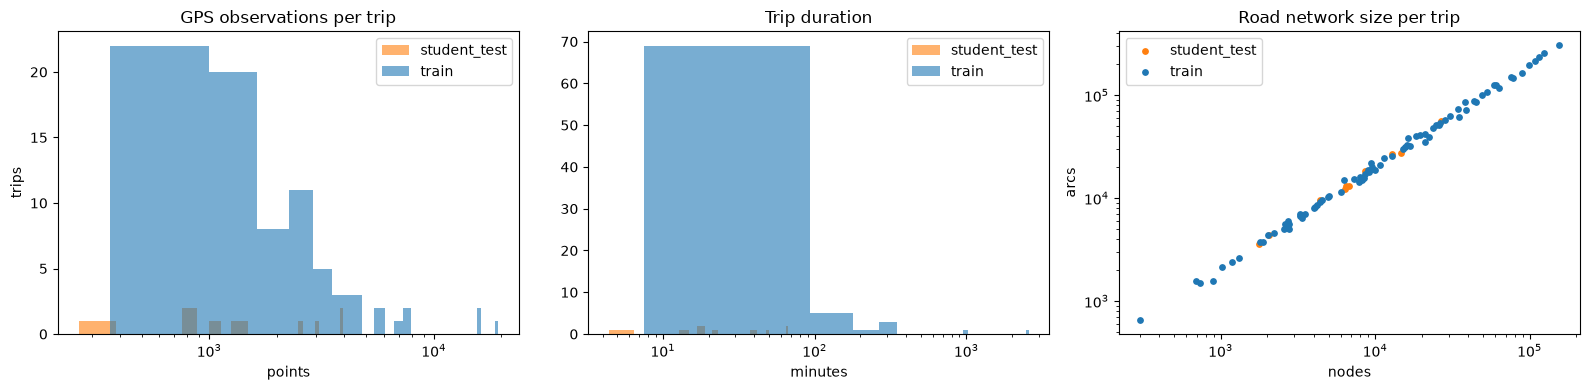

In [8]:
c = {"train": "tab:blue", "student_test": "tab:orange"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for p, g in inv.groupby("partition"):
    ax[0].hist(g.n_points, bins=30, alpha=.6, label=p, color=c[p])
    ax[1].hist(g.duration_min, bins=30, alpha=.6, label=p, color=c[p])
    ax[2].scatter(g.n_nodes, g.n_arcs, label=p, color=c[p], s=15)
ax[0].set(title="GPS observations per trip", xlabel="points", ylabel="trips", xscale="log")
ax[1].set(title="Trip duration", xlabel="minutes", xscale="log")
ax[2].set(title="Road network size per trip", xlabel="nodes", ylabel="arcs", xscale="log", yscale="log")
for a in ax: a.legend()
plt.tight_layout(); plt.savefig(OUT / "plots/01_trip_sizes.png", dpi=130); plt.show()

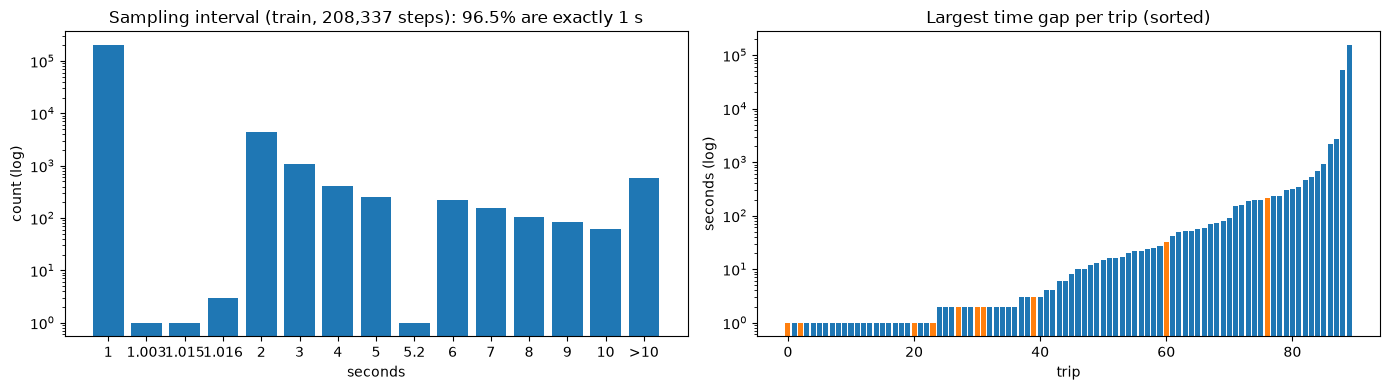

In [9]:
dt_all = np.concatenate([e["dt"] for (p, _), e in extras.items() if p == "train"])
vals, cnts = np.unique(np.clip(dt_all, 0, 11), return_counts=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar([f"{v:g}" if v < 11 else ">10" for v in vals], cnts); ax[0].set_yscale("log")
ax[0].set(title=f"Sampling interval (train, {len(dt_all):,} steps): {np.mean(dt_all==1):.1%} are exactly 1 s", xlabel="seconds", ylabel="count (log)")
s_ = inv.sort_values("dt_max_s")
ax[1].bar(range(len(s_)), s_.dt_max_s, color=[c[p] for p in s_.partition]); ax[1].set_yscale("log")
ax[1].set(title="Largest time gap per trip (sorted)", xlabel="trip", ylabel="seconds (log)")
plt.tight_layout(); plt.savefig(OUT / "plots/02_sampling_gaps.png", dpi=130); plt.show()

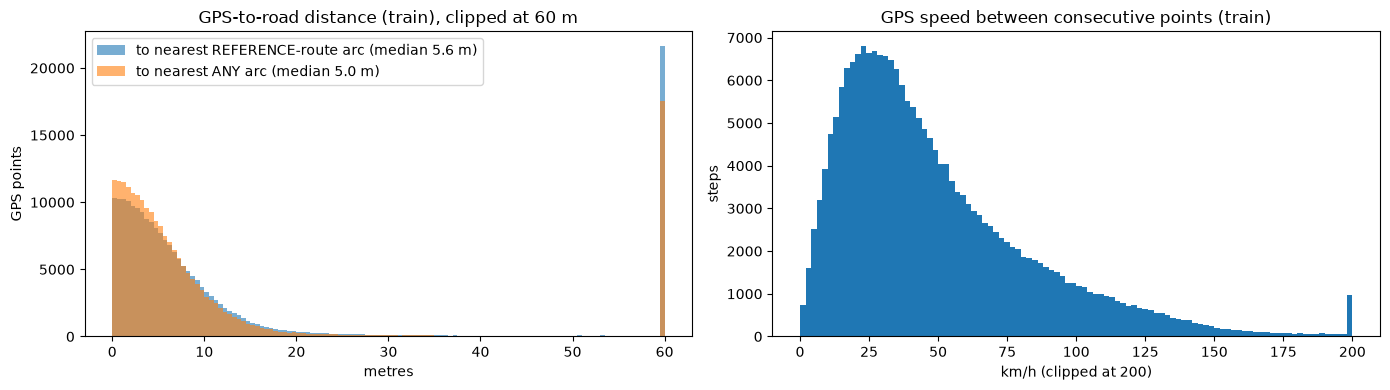

p50 distance GPS -> reference route:    5.6 m
p90 distance GPS -> reference route:   74.9 m
p95 distance GPS -> reference route:  140.2 m
p99 distance GPS -> reference route:  203.3 m
p99.9 distance GPS -> reference route:  335.5 m


In [10]:
d_rt = np.concatenate([e["d_route"] for (p, _), e in extras.items() if p == "train"])
d_any = np.concatenate([e["d_any"] for (p, _), e in extras.items() if p == "train"])
sp = np.concatenate([e["speed"] for (p, _), e in extras.items() if p == "train"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(np.clip(d_rt, 0, 60), bins=120, alpha=.6, label=f"to nearest REFERENCE-route arc (median {np.median(d_rt):.1f} m)")
ax[0].hist(np.clip(d_any, 0, 60), bins=120, alpha=.6, label=f"to nearest ANY arc (median {np.median(d_any):.1f} m)")
ax[0].set(title="GPS-to-road distance (train), clipped at 60 m", xlabel="metres", ylabel="GPS points"); ax[0].legend()
ax[1].hist(np.clip(sp[~np.isnan(sp)], 0, 200), bins=100)
ax[1].set(title="GPS speed between consecutive points (train)", xlabel="km/h (clipped at 200)", ylabel="steps")
plt.tight_layout(); plt.savefig(OUT / "plots/03_gps_noise_speed.png", dpi=130); plt.show()
for q in [50, 90, 95, 99, 99.9]:
    print(f"p{q} distance GPS -> reference route: {np.percentile(d_rt, q):6.1f} m")

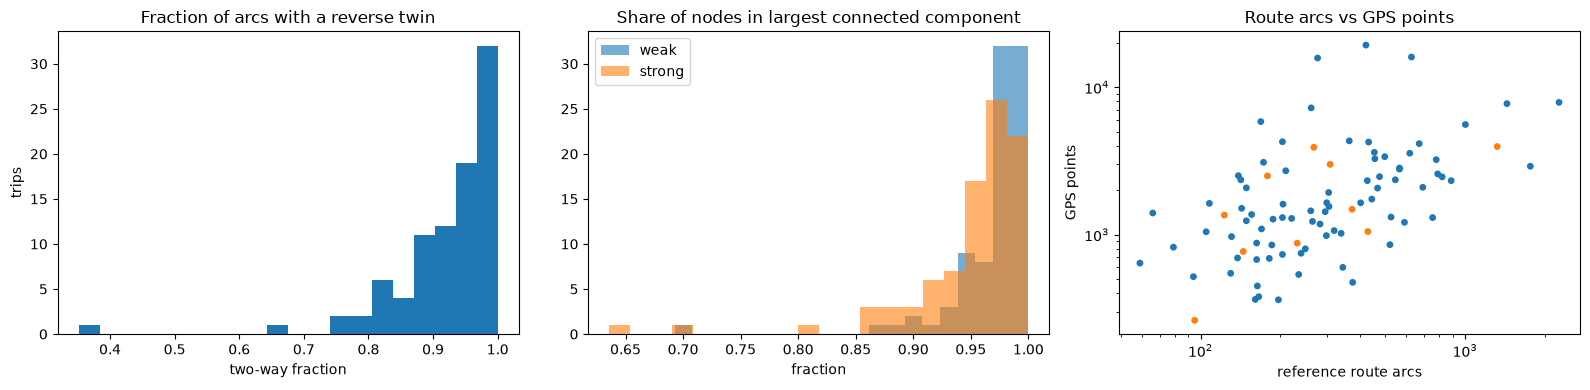

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(inv.two_way_frac, bins=20); ax[0].set(title="Fraction of arcs with a reverse twin", xlabel="two-way fraction", ylabel="trips")
ax[1].hist(inv.largest_wcc_frac, bins=20, alpha=.6, label="weak"); ax[1].hist(inv.largest_scc_frac, bins=20, alpha=.6, label="strong")
ax[1].set(title="Share of nodes in largest connected component", xlabel="fraction"); ax[1].legend()
ax[2].scatter(inv.n_route_arcs, inv.n_points, c=[c[p] for p in inv.partition], s=15)
ax[2].set(title="Route arcs vs GPS points", xlabel="reference route arcs", ylabel="GPS points", xscale="log", yscale="log")
plt.tight_layout(); plt.savefig(OUT / "plots/04_network_connectivity.png", dpi=130); plt.show()

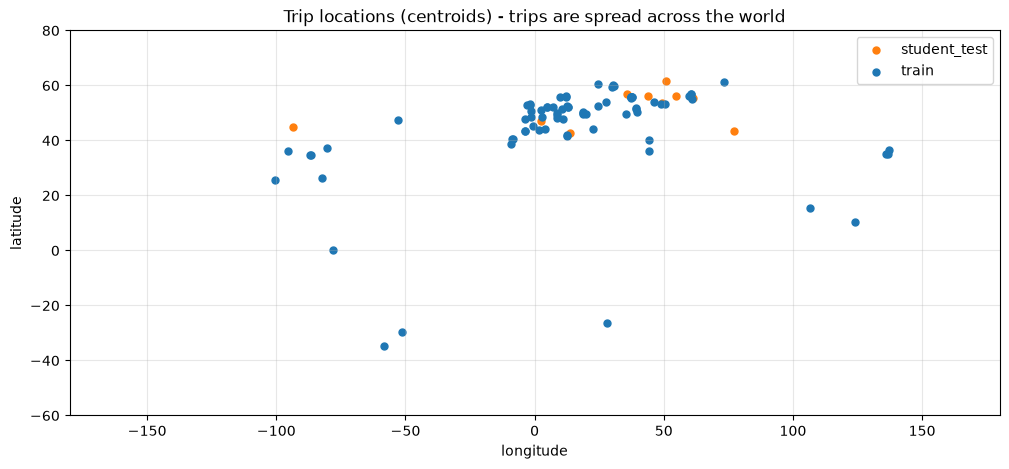

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
for p, g in inv.groupby("partition"):
    ax.scatter(g.lon_c, g.lat_c, color=c[p], label=p, s=25)
ax.set(title="Trip locations (centroids) - trips are spread across the world", xlabel="longitude", ylabel="latitude", xlim=(-180, 180), ylim=(-60, 80))
ax.grid(alpha=.3); ax.legend(); plt.savefig(OUT / "plots/05_trip_locations.png", dpi=130); plt.show()

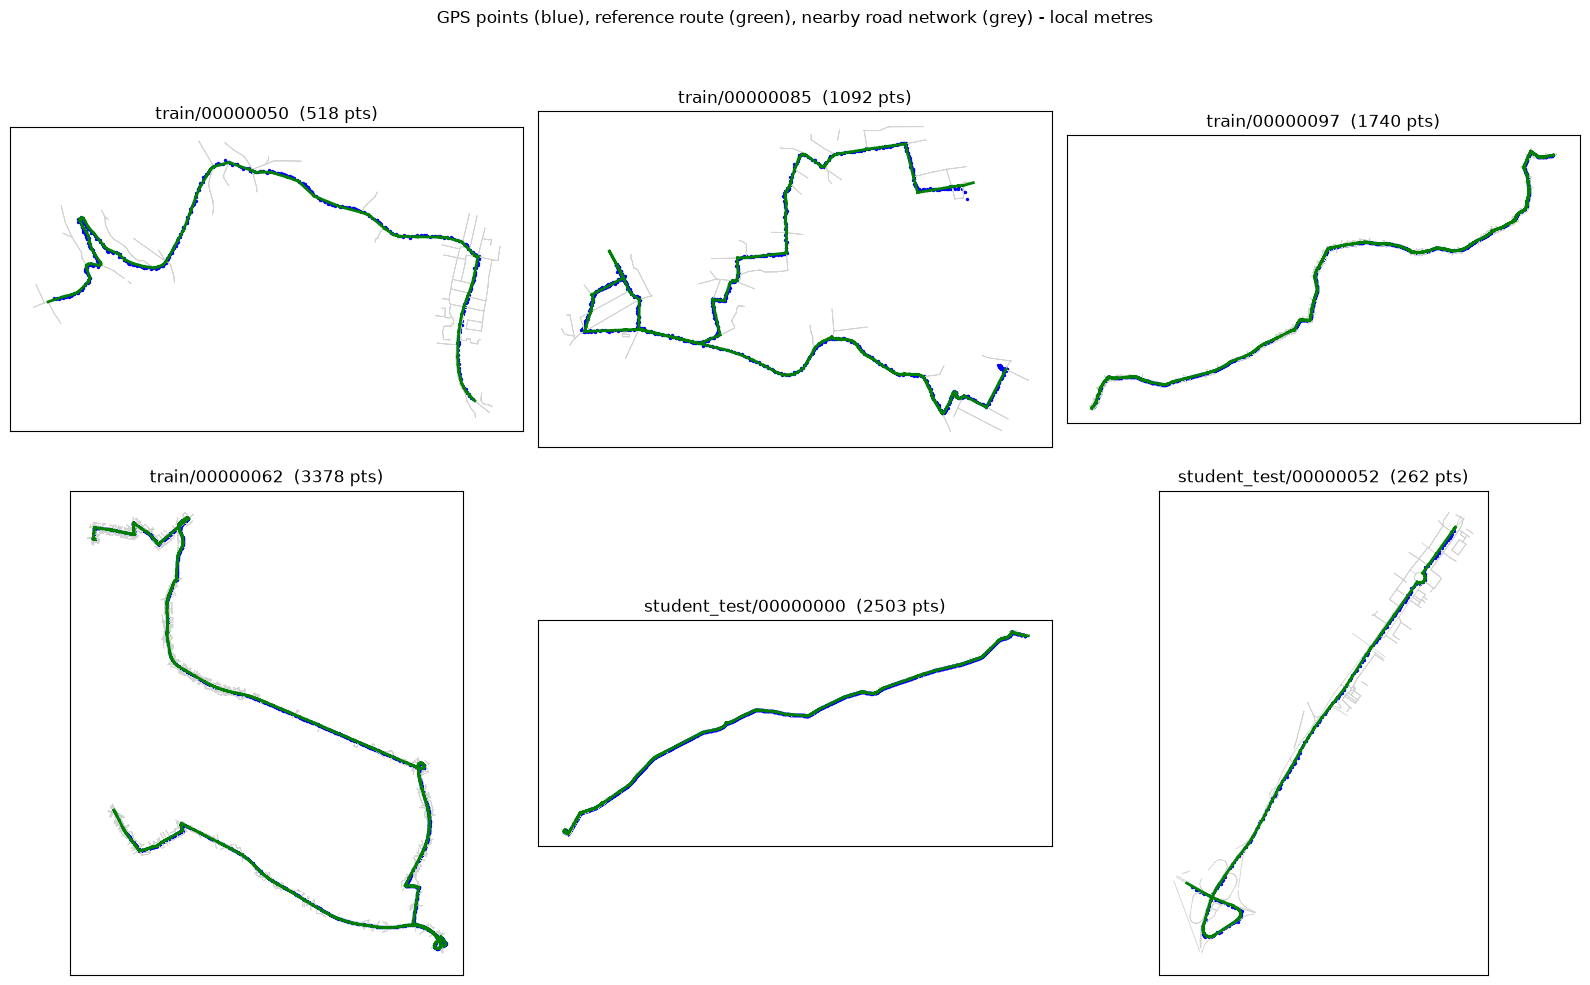

In [13]:
def plot_trip(ax, part, tid, margin=150):
    d = load_trip(part, tid); tr, nd, ar, rt = d["track"], d["nodes"], d["arcs"], d["route"]
    lon0, lat0 = tr.lon.mean(), tr.lat.mean()
    gx, gy = to_local_xy(tr.lon, tr.lat, lon0, lat0); nx_, ny_ = to_local_xy(nd.lon, nd.lat, lon0, lat0)
    near = cKDTree(np.column_stack([gx, gy])).query(np.column_stack([(nx_[ar.u] + nx_[ar.v]) / 2, (ny_[ar.u] + ny_[ar.v]) / 2]),
                                                    distance_upper_bound=margin)[0] < np.inf
    a = ar[near]
    ax.plot(np.vstack([nx_[a.u], nx_[a.v], np.full(len(a), np.nan)]).T.ravel(),
            np.vstack([ny_[a.u], ny_[a.v], np.full(len(a), np.nan)]).T.ravel(), color="lightgrey", lw=.6)
    r = ar.iloc[rt.arc_id.values]
    ax.plot(np.vstack([nx_[r.u], nx_[r.v], np.full(len(r), np.nan)]).T.ravel(),
            np.vstack([ny_[r.u], ny_[r.v], np.full(len(r), np.nan)]).T.ravel(), color="green", lw=2)
    ax.scatter(gx, gy, s=2, color="blue")
    ax.set(title=f"{part}/{tid}  ({len(tr)} pts)", aspect="equal"); ax.set_xticks([]); ax.set_yticks([])

sample = [("train", t) for t in inv[inv.partition == "train"].sort_values("n_points").trip_id.iloc[[5, 25, 45, 65]]] \
         + [("student_test", "00000000"), ("student_test", "00000052")]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (p, t) in zip(axes.ravel(), sample): plot_trip(ax, p, t)
fig.suptitle("GPS points (blue), reference route (green), nearby road network (grey) - local metres")
plt.tight_layout(); plt.savefig(OUT / "plots/06_trajectories.png", dpi=130); plt.show()

## 7. Interactive Folium maps
Layers: nearby road network, reference route, GPS observations, start/end markers, with a legend and layer control.
Saved to `outputs/eda/maps/`.

In [14]:
ESRI = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}"

def base_map(**kw):
    # Esri tiles load from file:// too; OSM tiles need a Referer, so they only work when served over http.
    m = folium.Map(tiles=None, **kw)
    folium.TileLayer(ESRI, attr="Tiles &copy; Esri", name="Esri street map").add_to(m)
    folium.TileLayer("OpenStreetMap", name="OpenStreetMap", show=False).add_to(m)   # hidden by default
    return m

LEGEND = '''<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;padding:8px 10px;
border:1px solid #888;border-radius:4px;font:13px sans-serif">
<b>{title}</b><br><span style="color:#999">&#9644;</span> Road network (nearby)<br>
<span style="color:green">&#9644;</span> Reference route<br><span style="color:blue">&#9679;</span> GPS observations{sub}<br>
<span style="color:#2a2">&#9873;</span> start &nbsp; <span style="color:#c22">&#9873;</span> end</div>'''

def trip_map(part, tid, margin=150, max_pts=3000):
    d = load_trip(part, tid); tr, nd, ar, rt = d["track"], d["nodes"], d["arcs"], d["route"]
    lon0, lat0 = tr.lon.mean(), tr.lat.mean()
    gx, gy = to_local_xy(tr.lon, tr.lat, lon0, lat0); nx_, ny_ = to_local_xy(nd.lon, nd.lat, lon0, lat0)
    mid = np.column_stack([(nx_[ar.u] + nx_[ar.v]) / 2, (ny_[ar.u] + ny_[ar.v]) / 2])
    near = cKDTree(np.column_stack([gx, gy])).query(mid, distance_upper_bound=margin)[0] < np.inf
    a = ar[near]
    a = a[~pd.DataFrame({"x": a[["u", "v"]].min(axis=1), "y": a[["u", "v"]].max(axis=1)}).duplicated().values]  # draw two-way roads once
    seg = lambda df: [[[nd.lat[i], nd.lon[i]], [nd.lat[j], nd.lon[j]]] for i, j in zip(df.u, df.v)]

    m = base_map()
    fg_net = folium.FeatureGroup("Road network (nearby)")
    folium.PolyLine(seg(a), color="#999", weight=1.5, opacity=.8).add_to(fg_net)
    fg_rt = folium.FeatureGroup("Reference route")
    folium.PolyLine(seg(ar.iloc[rt.arc_id.values]), color="green", weight=5, opacity=.8).add_to(fg_rt)
    step = max(1, len(tr) // max_pts)
    fg_gps = folium.FeatureGroup("GPS observations")
    for _, p in tr.iloc[::step].iterrows():
        folium.CircleMarker([p.lat, p.lon], radius=2, color="blue", fill=True, weight=0, fill_opacity=.7,
                            tooltip=f"t={p.t:.0f}s").add_to(fg_gps)
    for fg in (fg_net, fg_rt, fg_gps): fg.add_to(m)
    folium.Marker([tr.lat.iloc[0], tr.lon.iloc[0]], tooltip="start", icon=folium.Icon(color="green")).add_to(m)
    folium.Marker([tr.lat.iloc[-1], tr.lon.iloc[-1]], tooltip="end", icon=folium.Icon(color="red")).add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    m.fit_bounds([[tr.lat.min(), tr.lon.min()], [tr.lat.max(), tr.lon.max()]])
    sub = f" (every {step}th point)" if step > 1 else ""
    m.get_root().html.add_child(folium.Element(LEGEND.format(title=f"{part}/{tid}", sub=sub)))
    path = OUT / "maps" / f"{part}_{tid}.html"; m.save(path); print("saved", path.name)
    return m

trn = inv[inv.partition == "train"]
worst_p95 = trn.sort_values("gps2route_p95_m").trip_id.iloc[-1]      # noisy points far from route
worst_med = trn.sort_values("gps2route_median_m").trip_id.iloc[-1]   # whole track offset from route
for p, t in [("train", "00000001"), ("train", worst_p95), ("train", worst_med), ("student_test", "00000000")]:
    m_ = trip_map(p, t)
m_

saved train_00000001.html


saved train_00000002.html


saved train_00000054.html


saved student_test_00000000.html


In [15]:
world = base_map(location=[30, 10], zoom_start=2)
for _, r in inv.iterrows():
    folium.CircleMarker([r.lat_c, r.lon_c], radius=5, color="blue" if r.partition == "train" else "orange", fill=True,
                        tooltip=f"{r.partition}/{r.trip_id}: {r.n_points} pts, {r.n_arcs} arcs").add_to(world)
world.get_root().html.add_child(folium.Element(
    '<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;padding:6px;border:1px solid #888;font:13px sans-serif">'
    '<span style="color:blue">&#9679;</span> train &nbsp; <span style="color:orange">&#9679;</span> student_test</div>'))
world.save(OUT / "maps" / "all_trips_overview.html"); world

## 8. Key numbers for the data-quality log

In [16]:
tr_ = inv[inv.partition == "train"]
facts = {
    "trips (train / student_test)": f"{(inv.partition=='train').sum()} / {(inv.partition=='student_test').sum()}",
    "all 4 files present in every trip": bool(inv[["track_kb", "nodes_kb", "arcs_kb", "route_kb"]].notna().all().all()),
    "GPS points total (train)": int(tr_.n_points.sum()),
    "share of 1 s steps (train)": f"{np.mean(dt_all == 1):.2%}",
    "trips with a gap > 30 s": int((inv.dt_max_s > 30).sum()),
    "max projection error % (local metres vs haversine)": round(inv.proj_err_max_pct.max(), 4),
    "two-way arc fraction (median)": round(inv.two_way_frac.median(), 3),
    "trips whose route is fully connected": int((inv.route_connected_frac == 1).sum()),
    "median / p95 GPS->route distance, train (m)": f"{np.median(d_rt):.1f} / {np.percentile(d_rt, 95):.1f}",
    "GPS points > 50 m from reference route (train)": f"{np.mean(d_rt > 50):.3%}",
}
pd.Series(facts, name="value").to_frame()

,value
trips (train / student_test),80 / 10
all 4 files present in every trip,True
GPS points total (train),208417
share of 1 s steps (train),96.50%
trips with a gap > 30 s,30
max projection error % (local metres vs haversine),0.1573
two-way arc fraction (median),0.951
trips whose route is fully connected,79
"median / p95 GPS->route distance, train (m)",5.6 / 140.2
GPS points > 50 m from reference route (train),10.822%


## 9. Trips whose GPS is systematically far from the reference route
A few trips have a *median* GPS-to-route distance above 50 m. This is not normal GPS noise (median elsewhere is ~5 m).
Below we measure the median offset vector GPS -> nearest route point and test whether a single constant shift explains it.

In [17]:
def offset_check(part, tid, iters=5):
    d = load_trip(part, tid); tr, nd, ar, rt = d["track"], d["nodes"], d["arcs"], d["route"]
    lon0, lat0 = tr.lon.mean(), tr.lat.mean()
    gx, gy = to_local_xy(tr.lon, tr.lat, lon0, lat0); nx_, ny_ = to_local_xy(nd.lon, nd.lat, lon0, lat0)
    L = arc_lines(np.column_stack([nx_, ny_]), ar.iloc[np.unique(rt.arc_id)]); tree = shapely.STRtree(L)
    def dists(sh):
        P = shapely.points(gx + sh[0], gy + sh[1]); idx = tree.query_nearest(P, all_matches=False)[1]
        c = shapely.get_coordinates(shapely.shortest_line(P, L[idx])).reshape(-1, 2, 2)
        return c[:, 1] - c[:, 0]
    sh = np.zeros(2)
    for _ in range(iters): sh += np.median(dists(sh), axis=0)
    before, after = np.hypot(*dists(np.zeros(2)).T), np.hypot(*dists(sh).T)
    return {"trip_id": tid, "best_shift_dx_m": sh[0], "best_shift_dy_m": sh[1], "median_before_m": np.median(before),
            "median_after_shift_m": np.median(after), "far50_before": (before > 50).mean(), "far50_after_shift": (after > 50).mean()}

off = inv[inv.gps2route_median_m > 50]
pd.DataFrame([offset_check(r.partition, r.trip_id) for r in off.itertuples()]).round(3)

,trip_id,best_shift_dx_m,best_shift_dy_m,median_before_m,median_after_shift_m,far50_before,far50_after_shift
0,00000033,-0.214,126.874,122.383,17.080,0.588,0.277
1,00000054,-3.604,-134.347,138.514,28.909,0.872,0.204


## 10. Data-quality log: findings, assumptions and decisions
*(numbers from the cells above; train + student_test only)*

| # | Finding | Decision for the pipeline |
|---|---------|---------------------------|
| 1 | All 90 trips have all 4 files; no NaNs, no invalid coordinates, timestamps strictly increasing, all arc/route ids valid. | No imputation needed. Still validate on load (API input is a trust boundary). |
| 2 | ~96.5% of steps are exactly 1 s, but 30 trips have a gap > 30 s; extreme gaps: trip 90 (~42 h), 78 (~14.7 h), 69 (~44 min). | Split a trip into independent segments when the gap exceeds a threshold; relax HMM transitions for moderate gaps. |
| 3 | Trips are worldwide (each with its own road network, 300 - 155k nodes). | Per-trip local metric projection (error vs haversine < 0.2%, measured above). Never use degree distances. |
| 4 | Road graph is directed; median 95% of arcs have a reverse twin, so one-way streets exist. Graphs are not fully strongly connected (largest SCC median ~96% of nodes). Some duplicate arcs, zero-length arcs and self-loops exist. | Keep direction (matters for HMM transitions). Treat duplicates as separate candidates or deduplicate; handle unreachable candidate pairs as invalid transitions. |
| 5 | Reference routes are ordered arc lists, almost always connected end-to-end (79 of 90 trips fully connected; the rest have a few breaks), and **not aligned to GPS points**. | Build per-point labels ourselves by an order-preserving alignment of GPS points to route arcs (Step 2). |
| 6 | Median GPS-to-route distance is ~5.6 m, but the tail is long (p95 ~140 m), driven mainly by trips 54 and 33, whose GPS sits ~120-140 m from the route (not a clean constant shift). Trip 2 has a large off-route stretch. | Treat the reference route as imperfect. Points with no route arc within the candidate radius get no label (excluded from training, reported separately), not forced labels. |
| 7 | Some speed jumps > 200 km/h (917 steps in train), mostly in highway trips (e.g. trip 1, median 149 km/h). | Use speed as a feature, cap it; do not drop points. |